In [1]:
import model
from multiregion import multiregion_model
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


In [62]:
N = 39.5e6
T_osc = lambda t: 1.56 + 0.54 * np.cos(np.pi*t/180)

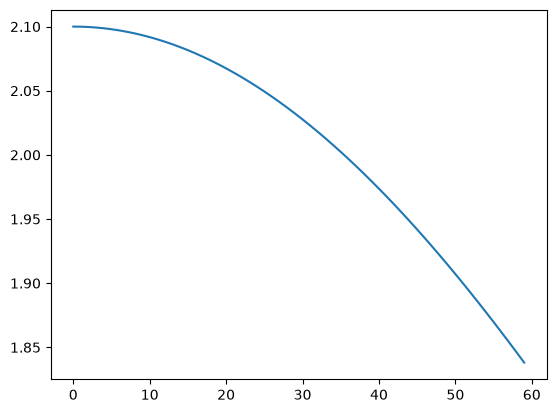

In [63]:
x = np.arange(0,60,1)
y = T_osc(x)
plt.plot(x,y)

In [73]:
osc = model.model(sigma=1,T=T_osc,N=N,gamma=0.0,alpha=1/3,model_function="basic_SIR",initial_status=[N-1,1,0])
lo = model.model(sigma=1,T=0.92/3,N=N,gamma=0.0,alpha=1/3,model_function="basic_SIR",initial_status=[N-1,1,0])
hi = model.model(sigma=1,T=2.52/3,N=N,gamma=0.0,alpha=1/3,model_function="basic_SIR",initial_status=[N-1,1,0])

In [74]:
TOTAL = multiregion_model([osc,lo,hi],model_function="basic_SIR")

In [75]:
t,status = TOTAL.euler_solver(delta_t=0.2,T_max=60)


100%|██████████| 299/299 [00:00<00:00, 30819.25it/s]


In [78]:
S = status[:,0, 0]
I = status[:,0, 1]
R = status[:,0, 2]

In [86]:
np.argmax(I)

np.int64(185)

In [87]:
t[185]

np.float64(37.0)

In [89]:
I[185]

np.float64(9538032.570649743)

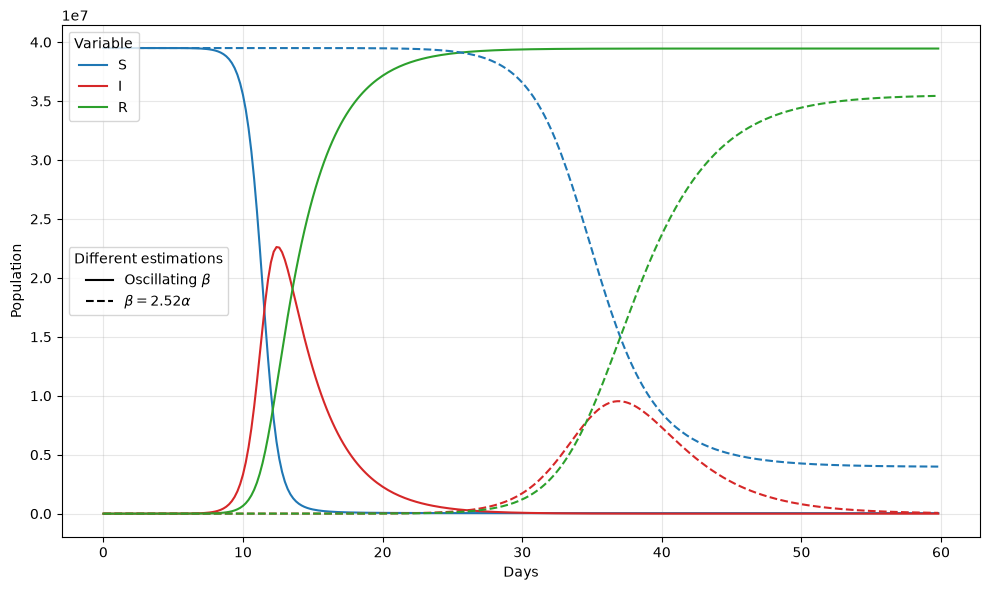

In [85]:
S = status[:,0, 0]
I = status[:,0, 1]
R = status[:,0, 2]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t, S, label="S", color="tab:blue")
ax.plot(t, I, label="I", color="tab:red")
ax.plot(t, R, label="R", color="tab:green")

S = status[:,2, 0]
I = status[:,2, 1]
R = status[:,2, 2]

ax.plot(t, S, label="S", color="tab:blue",linestyle="dashed")
ax.plot(t, I, label="I", color="tab:red",linestyle="dashed")
ax.plot(t, R, label="R", color="tab:green",linestyle="dashed")

ax.set_xlabel("Days")
ax.set_ylabel("Population")
# Legend for the colored variables
variable_legend = ax.legend(
    handles=[
        Line2D([], [], color="tab:blue", label="S"),
        Line2D([], [], color="tab:red", label="I"),
        Line2D([], [], color="tab:green", label="R"),
    ],
    title="Variable",
    loc="upper left",
)
ax.add_artist(variable_legend)  # Keep this legend when adding the second

# Legend for the scenarios
ax.legend(
    handles=[
        Line2D([], [], color="black", linestyle="-", label=r"Oscillating $\beta$"),
        Line2D([], [], color="black", linestyle="--", label=r"$\beta=2.52\alpha$"),
    ],
    title="Different estimations",
    loc="center left",
)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()